In [ ]:
import numpy as np, matplotlib
import matplotlib.pyplot as plt
from scipy.special import wofz
cte = {
    "c[m/s]": 299792458,
    "hbar[Js]": 1.054571817e-34,
    "kB[J/K]": 1.380649e-23,
    "m[Kg]": 2.20693935795e-25,
    "T[K]":  296,
    "E6P3/2[THz]": 351.72571847490013,
    "E8S1/2[THz]": 729.0097990179224,
    "lmd1[nm]": 822.4648239402601,
    "lmd2[nm]": 794.6066994624074,
    "lmd3[nm]": 852.347275882795,
    "k1[rad/m]": 7639457.791128544,
    "k2[rad/m]": 7907289.620677106,
    "k3[rad/m]": 7371625.961579981,
    "gamma_ba[1e6*rad/s]": np.pi*5.2227,
    "gamma_ca[1e6*rad/s]": 9.615384615384617/2
}
Z=lambda z: 1j*np.sqrt(np.pi)*wofz(z)
u=np.sqrt(2*cte["kB[J/K]"]*cte["T[K]"]/cte["m[Kg]"])

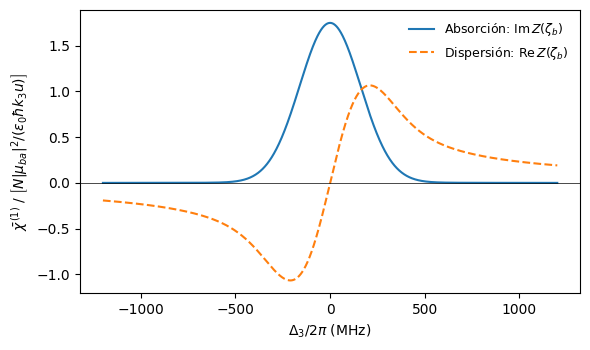

In [ ]:
D3=np.linspace(-1200,1200,2001)
gba = cte["gamma_ba[1e6*rad/s]"]
k3 = cte["k3[rad/m]"]
ku = k3*u/1e6
zb=(-2*np.pi*D3+1j*gba)/ku; Zb=Z(zb)

fig,ax=plt.subplots(figsize=(6,3.6))
ax.plot(D3,Zb.imag,'C0',label=r'Absorción: $\mathrm{Im}\,Z(\zeta_b)$')
ax.plot(D3,Zb.real,'C1--',label=r'Dispersión: $\mathrm{Re}\,Z(\zeta_b)$')
ax.axhline(0,color='k',lw=0.5)
ax.set_xlabel(r'$\Delta_3/2\pi$ (MHz)'); ax.set_ylabel(r'$\bar\chi^{(1)}\ /\ \left[N|\mu_{ba}|^2/(\varepsilon_0\hbar k_3u)\right]$')
ax.legend(frameon=False,fontsize=9); fig.tight_layout();
plt.savefig("chi-1.png")

In [ ]:
(ku/np.sqrt(np.pi))/(2*np.pi)

np.float64(127.38426364865458)

In [ ]:
gba

16.40759595190341

In [ ]:
# Figura 4.2
d2=np.linspace(-1500,1500,601)*MHz; d3=np.linspace(-1000,1000,401)*MHz
D2,D3g=np.meshgrid(d2,d3)
za=(-D2+1j*gca)/(2*k1*u); zb=(-D3g+1j*gba)/(k3*u)
F=np.abs((Z(za)-Z(zb))/(za-zb))
print('max F',F.max(),'at', D2.flat[F.argmax()]/MHz, D3g.flat[F.argmax()]/MHz)
fig,ax=plt.subplots(figsize=(6,4))
cs=ax.contourf(D2/MHz,D3g/MHz,F/F.max(),levels=20,cmap='viridis')
cb=fig.colorbar(cs); cb.set_label('Magnitud normalizada')
ax.plot(d2/MHz,(k3/(2*k1))*d2/MHz,'w--',lw=1,label=r'$\Delta_3=(k_3/2k_1)\,\Delta_2$')
ax.set_xlabel(r'$\Delta_2/2\pi$ (MHz)'); ax.set_ylabel(r'$\Delta_3/2\pi$ (MHz)')
ax.legend(loc='upper left',fontsize=9); fig.tight_layout(); fig.savefig('figuras/fig4_2_chi3_doppler.pdf')
# chequeos
print('Z(0)',Z(1e-6j),'Zprime num',(Z(1e-3+1e-6j)-Z(-1e-3+1e-6j))/2e-3)
print('k3/2k1',k3/(2*k1),'u',u,'reduction',gca*gba/(k1*k3*u**2))
# check ridge: for fixed D2=600MHz, argmax over D3
i=np.argmin(abs(d2/MHz-600)); print('ridge at D2=600:', d3[F[:,i].argmax()]/MHz, 'expected',k3/(2*k1)*600)